# 01 - Exploration du jeu de données CEDAR
Objectif : comprendre les données avant d'entraîner quoi que ce soit.
Ce notebook se lance depuis le dossier `notebooks/`.

In [1]:
import sys
sys.path.append("../src")

import random
import matplotlib.pyplot as plt
from dataset import index_signatures, split_by_person, SignaturePairDataset
from preprocessing import preprocess_signature

DATA_DIR = "../data/raw"

## 1. Combien de personnes et d'images ?

In [2]:
people = index_signatures(DATA_DIR)
n_orig = sum(len(p["orig"]) for p in people.values())
n_forg = sum(len(p["forg"]) for p in people.values())

print(f"Personnes : {len(people)}")
print(f"Signatures authentiques : {n_orig}")
print(f"Falsifications : {n_forg}")
print(f"Par personne (exemple) : {len(people[1]['orig'])} vraies, {len(people[1]['forg'])} fausses")

Personnes : 55
Signatures authentiques : 1320
Falsifications : 1320
Par personne (exemple) : 24 vraies, 24 fausses


## 2. À quoi ressemblent les signatures ? (images brutes)

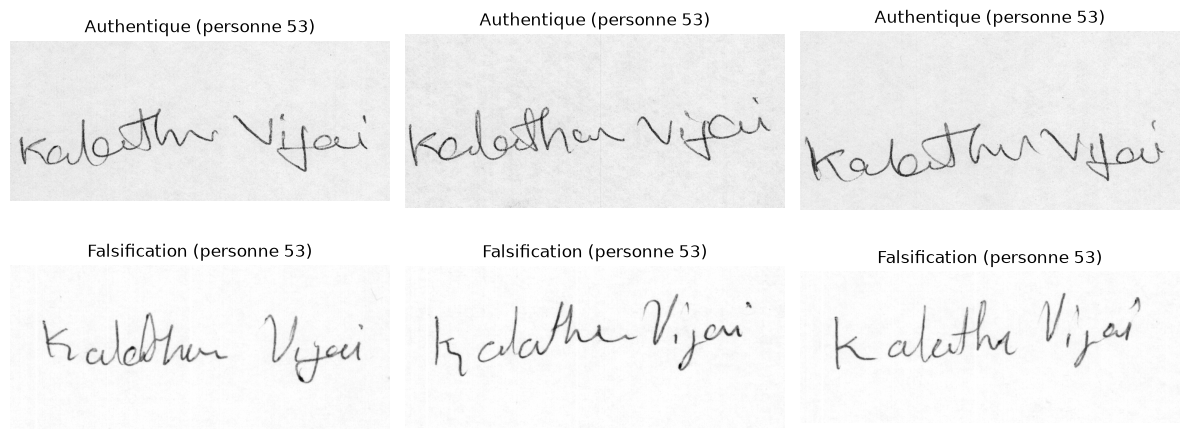

In [3]:
import cv2

pid = random.choice(list(people))
orig = random.sample(people[pid]["orig"], 3)
forg = random.sample(people[pid]["forg"], 3)

fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for ax, path in zip(axes[0], orig):
    ax.imshow(cv2.imread(str(path), 0), cmap="gray"); ax.set_title(f"Authentique (personne {pid})"); ax.axis("off")
for ax, path in zip(axes[1], forg):
    ax.imshow(cv2.imread(str(path), 0), cmap="gray"); ax.set_title(f"Falsification (personne {pid})"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Avant / après prétraitement

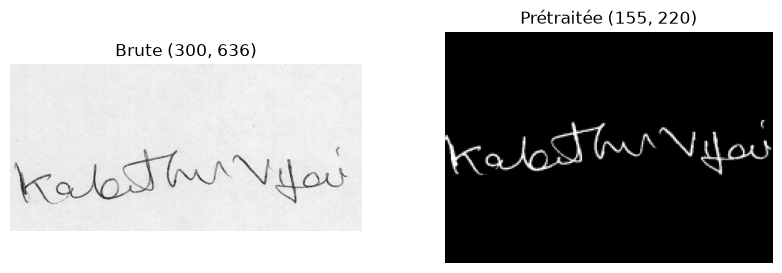

In [4]:
path = people[pid]["orig"][0]
raw = cv2.imread(str(path), 0)
clean = preprocess_signature(path)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].imshow(raw, cmap="gray"); axes[0].set_title(f"Brute {raw.shape}"); axes[0].axis("off")
axes[1].imshow(clean, cmap="gray"); axes[1].set_title(f"Prétraitée {clean.shape}"); axes[1].axis("off")
plt.show()

## 4. Séparation train / validation / test (par personne)

In [5]:
train, val, test = split_by_person(people)
print(f"train : {len(train)} personnes | val : {len(val)} | test : {len(test)}")

train : 39 personnes | val : 8 | test : 8


## 5. Quelques paires générées (1 = authentique, 0 = différente)

780 paires dans le jeu d'entraînement


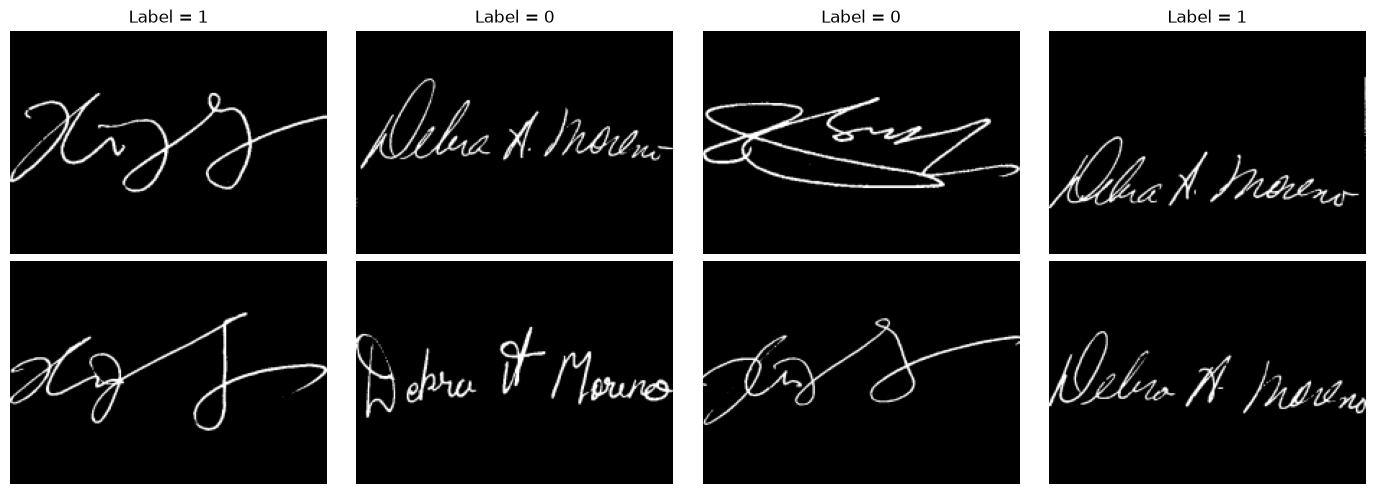

In [6]:
ds = SignaturePairDataset(train, pairs_per_person=20)
print(f"{len(ds)} paires dans le jeu d'entraînement")

fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for i in range(4):
    x1, x2, y = ds[i]
    axes[0][i].imshow(x1[0], cmap="gray"); axes[0][i].set_title(f"Label = {int(y)}"); axes[0][i].axis("off")
    axes[1][i].imshow(x2[0], cmap="gray"); axes[1][i].axis("off")
plt.tight_layout(); plt.show()